### Основные задания

#### Импорты и константы

In [95]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import solve

ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'data'
DATA_TASK_1_GEG = DATA_DIR / 'global-electricity-generation.csv'
DATA_TASK_1_GEC = DATA_DIR / 'global-electricity-consumption.csv'
DATA_TASK_2 = DATA_DIR / 'data2.csv'

#### Задача №1

В файле «global-electricity-generation.csv»  представлена информация о производстве электроэнергии странами с 1992 по 2021 год.

В файле «global-electricity-consumption.csv» – информация о потреблении электроэнергии.

Все данные – в млрд. кВт*ч. 

1. Загрузите информацию из этих файлов.

In [96]:
geg_values = np.genfromtxt(fname=DATA_TASK_1_GEG, delimiter=',', skip_header=1, dtype=float, usecols=range(1, 31), missing_values=['--', 'ie'])
geg_countries = np.genfromtxt(fname=DATA_TASK_1_GEG, delimiter=',', skip_header=1, usecols=(0), dtype=str)

gec_values = np.genfromtxt(fname=DATA_TASK_1_GEC, delimiter=',', skip_header=1, dtype=float, usecols=range(1, 31), missing_values=['--', 'ie'])
gec_countries = np.genfromtxt(fname=DATA_TASK_1_GEC, delimiter=',', skip_header=1, usecols=(0), dtype=str)

2. Постройте  одномерные  массивы  ежегодного  производства  и  потребления электроэнергии в среднем за последние 5 лет (один массив –  производство по всем странам, второй – потребление по всем странам).

In [97]:
avg_geg_last_5_years = np.nanmean(geg_values[:, -5:], axis=1)
avg_geg_last_5_years # производство электроэнергии в среднем за последние 5 лет

C:\Users\mir-2\AppData\Local\Temp\ipykernel_12620\3203503529.py:1: RuntimeWarning: Mean of empty slice
  avg_geg_last_5_years = np.nanmean(geg_values[:, -5:], axis=1)


array([7.41112260e+01, 1.43874744e+01, 2.34131456e-01, 2.61904963e+00,
       1.68525657e+00, 3.22467278e-01, 4.54395253e-01, 8.16256728e+00,
       1.51080800e-01, 3.04534474e-01, 1.09982400e-01, 3.46618650e+00,
       1.07938681e+01, 1.02415954e+01, 5.62689348e-02, 1.96525003e+02,
       1.38324531e+00, 4.32897812e-01, 7.24914010e-01, 1.40118137e+01,
       2.21974979e+00, 3.04308759e-01, 1.70062066e+01, 2.26220932e+00,
       8.17928000e-02, 1.14018428e+01, 5.16513600e-01, 5.66646400e-01,
       3.14437064e+01, 2.11425569e+00, 1.71065787e+00, 3.34671057e+00,
       1.73598681e+00, 2.93215213e+00, 3.69605384e+01, 1.83195429e+01,
       1.60757200e+00, 5.10454400e-01, 3.14969886e+01,            nan,
       8.81083240e-01, 8.24189840e-03, 9.15092800e-02, 5.03165820e+00,
       5.49390560e-01, 2.19189181e-01, 3.65736000e-01, 2.29317837e+02,
       1.61017626e+01, 7.59917067e+00, 6.50779101e-01, 1.99460140e+01,
       4.27968892e+00, 0.00000000e+00, 1.56093650e+01, 8.07844052e+00,
      

In [98]:
avg_gec_last_5_years = np.nanmean(gec_values[:, -5:], axis=1)
avg_gec_last_5_years # потребление электроэнергии в среднем за последние 5 лет

array([6.42803544e+01, 1.27653183e+01, 8.58189599e-01, 3.58826363e+00,
       2.41878548e+00, 3.82465344e-01, 3.24550525e-01, 6.29769097e+00,
       1.41080800e-01, 2.58224474e-01, 7.91329572e-02, 1.89292936e+00,
       9.14616935e+00, 7.13665301e+00, 4.86108935e-01, 1.62099726e+02,
       1.23781144e+00, 3.87190135e-01, 1.53008067e+00, 9.38130450e+00,
       2.26861875e+00, 2.48527700e-01, 1.48627770e+01, 1.97219221e+00,
       7.69927572e-02, 8.98877963e+00, 8.71692421e-01, 5.21821968e-01,
       2.57338143e+01, 1.99484721e+00, 1.25450987e+00, 2.63071057e+00,
       1.71492681e+00, 2.76459213e+00, 3.23970288e+01, 1.29471296e+01,
       4.03877769e+00, 1.24842729e+00, 2.65907604e+01, 0.00000000e+00,
       7.63313793e-01, 6.68429840e-03, 7.96126994e-02, 4.69778520e+00,
       5.19450560e-01, 1.40589181e-01, 3.43532629e-01, 2.00649088e+02,
       1.29074315e+01, 6.64550422e+00, 1.25039930e+00, 1.59869786e+01,
       2.94686172e+00, 0.00000000e+00, 1.28555071e+01, 8.11025916e+00,
      

3.  Напишите выражения, позволяющие получить ответ на следующие вопросы:

- 3.1. Суммарное (по всем странам) потребление электроэнергии за каждый год.

In [99]:
sum_gec_for_years = np.nansum(gec_values, axis=0)
sum_gec_for_years

array([10569.01620096, 10854.56291897, 11104.65383426, 11476.47904131,
       11805.86547273, 12122.03311393, 12419.80887326, 12685.75413125,
       13230.24950221, 13486.48970448, 13938.77879299, 14455.56232878,
       15128.09797911, 15725.98237628, 16438.21377084, 17205.11980814,
       17477.47100677, 17435.68735807, 18748.16072401, 19438.82349584,
       19918.25495428, 20573.09641373, 20981.239762  , 21400.01776982,
       22022.68687939, 22716.20610151, 23530.92004845, 23915.65649767,
       23959.68010944, 25336.70701018])

- 3.2. Максимальное количество электроэнергии, которое произвела одна страна за один год

In [100]:
max_geg = np.nanmax(geg_values)
max_geg

np.float64(8151.518231)

- 3.3. Список  стран,  которые  производят  более  500  млрд.  кВт*ч  электроэнергии ежегодно в среднем за последние 5 лет

In [101]:
countries_idx, = np.where(avg_geg_last_5_years > 500)
geg_countries[countries_idx]

array(['Russia', 'France', 'Germany', 'China', 'India', 'Japan',
       'South Korea', 'Canada', 'United States', 'Brazil'], dtype='<U25')

- 3.4. 10% стран, которые потребляют больше всего электроэнергии ежегодно в среднем  за  последние  5  лет

In [102]:
q90 = np.nanpercentile(avg_gec_last_5_years, q=90)
top_10p_countries_idx, = np.where(avg_gec_last_5_years >= q90)
gec_countries[top_10p_countries_idx]

array(['South Africa', 'Russia', 'France', 'Germany', 'Italy', 'Spain',
       'Turkiye', 'United Kingdom', 'Australia', 'China', 'India',
       'Indonesia', 'Japan', 'South Korea', 'Taiwan', 'Vietnam', 'Iran',
       'Saudi Arabia', 'Canada', 'Mexico', 'United States', 'Brazil'],
      dtype='<U25')

- 3.5. Список стран, которые увеличили производство электроэнергии в 2021 году по сравнению с 1992 годом более, чем в 10 раз.

In [103]:
ration_1992_2021 = np.divide(geg_values[:, -1], geg_values[:, 0], out=None, where=geg_values[:, 0] > 0)
increase_geg_1992_to_2021_idx = np.where(ration_1992_2021 > 10)
geg_countries[increase_geg_1992_to_2021_idx]

array(['Angola', 'Benin', 'Equatorial Guinea', 'Ethiopia', 'Mali',
       'Mauritania', 'Mozambique', 'Sudan', 'Serbia', 'Slovakia',
       'Cambodia', 'China', 'Laos', 'Maldives', 'Vietnam', 'Wake Island',
       'Palestinian Territories', 'Turks and Caicos Islands'],
      dtype='<U25')

- 3.6. Список стран, которые в сумме за все годы потратили больше 100 млрд. кВт*ч электроэнергии и при этом произвели меньше, чем потратили. 

In [104]:
sum_gec_countries_all_years = np.nansum(gec_values, axis=1)
sum_geg_countries_all_years = np.nansum(geg_values, axis=1)
difference = sum_gec_countries_all_years - sum_geg_countries_all_years
lazy_countries_more_than_100_idx, = np.where((sum_gec_countries_all_years > 100) & (difference > 0))
gec_countries[lazy_countries_more_than_100_idx]

array(['Zimbabwe', 'Belarus', 'Moldova', 'Belgium', 'Croatia', 'Finland',
       'Hungary', 'Italy', 'Latvia', 'Luxembourg', 'Netherlands',
       'North Macedonia', 'Hong Kong'], dtype='<U25')

- 3.7. Какая страна потратила наибольшее количество электроэнергии в 2020 году?

In [105]:
max_gec_county_idx = np.nanargmax(gec_values[:, -2])
gec_countries[max_gec_county_idx]

np.str_('China')

#### Задача №2

В файле «data2.csv» представлены данные наблюдений о прибыли (второй столбец) в зависимости от установленной скидки на товар (первый столбец).

Бизнес-консультанты считают, что реальная зависимость прибыли от установленной скидки может быть описана квадратичной или кубической функцией (то есть полиномом второй или третьей степени, f(x) = a2x2+a1x+a0 или f(x) = a3x3+a2x2+a1x+a0).

0. Загрузка информации из файла

In [106]:
data = np.genfromtxt(DATA_TASK_2, delimiter=';', dtype=float, encoding='utf-8-sig')

In [107]:
x, y = data[:, 0], data[:, 1]
order = np.argsort(x)
x_sorted, y_sorted = x[order], y[order]
n = len(x_sorted)

1. Сформируйте систему линейных уравнений (СЛУ) для полинома 2й степени.

In [108]:
idx2 = [0, n // 2, n - 1]
x2 = x_sorted[idx2]; y2 = y_sorted[idx2]
a2 = np.vander(x2, 3)


2.  Решите  СЛУ,  тем  самым  найдя  коэффициенты полинома.

In [109]:
c2 = solve(a2, y2)

3. Получите вектор значений построенного полинома для заданных точек.

In [110]:
y_fit2 = np.polyval(c2, x)


4. Постройте в одной области два графика: один по заданным в файле точкам, другой – по полученному вектору. 

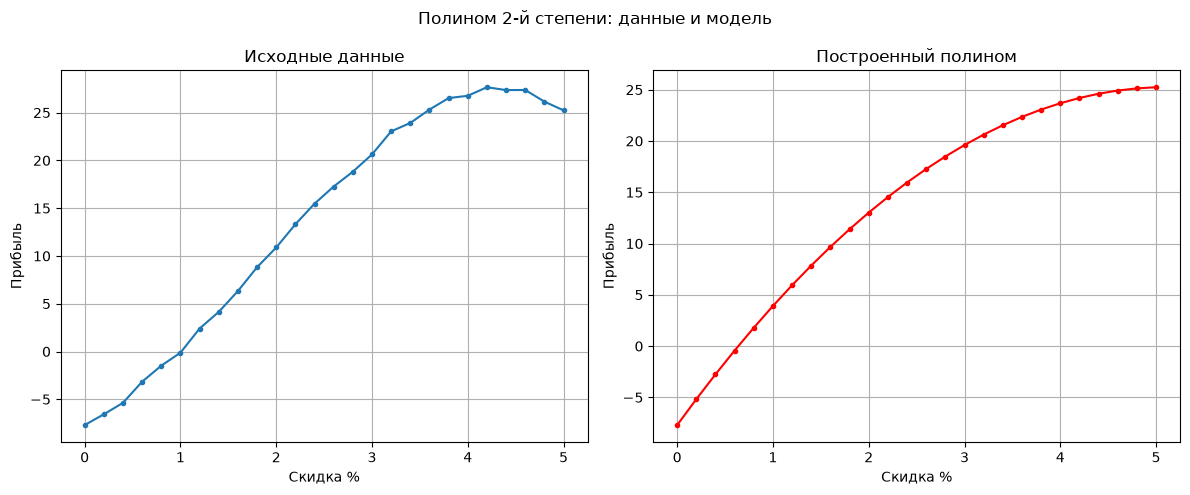

In [111]:
fig1, axs1 = plt.subplots(1, 2, figsize=(12, 5))
fig1.suptitle('Полином 2-й степени: данные и модель')
axs1[0].plot(x, y, marker='.')
axs1[0].set_title('Исходные данные')
axs1[0].set(xlabel='Скидка %', ylabel='Прибыль')
axs1[0].grid(True)
axs1[1].plot(x, y_fit2, color='red', marker='.')
axs1[1].set_title('Построенный полином')
axs1[1].set(xlabel='Скидка %', ylabel='Прибыль')
axs1[1].grid(True)
plt.tight_layout()
plt.show()

5. Посчитайте значение квадратичного отклонения RSS (оно вычисляется по формуле 𝑅𝑆𝑆=∑ (𝑦𝑖 −𝑓(𝑥𝑖))2𝑛𝑖=1 , где  yi – ожидаемые  значения  (из  исходного  файла),  f(xi) – рассчитанные значения полинома). 

In [112]:
rss2 = np.sum((y - y_fit2) ** 2)

6. Повторите шаги 1-5 для полинома 3й степени.

In [113]:
idx3 = [0, n // 3, 2 * n // 3, n - 1]
x3 = x_sorted[idx3]; y3 = y_sorted[idx3]
a3 = np.vander(x3, 4)
c3 = solve(a3, y3)
y_fit3 = np.polyval(c3, x)
rss3 = np.sum((y - y_fit3) ** 2)

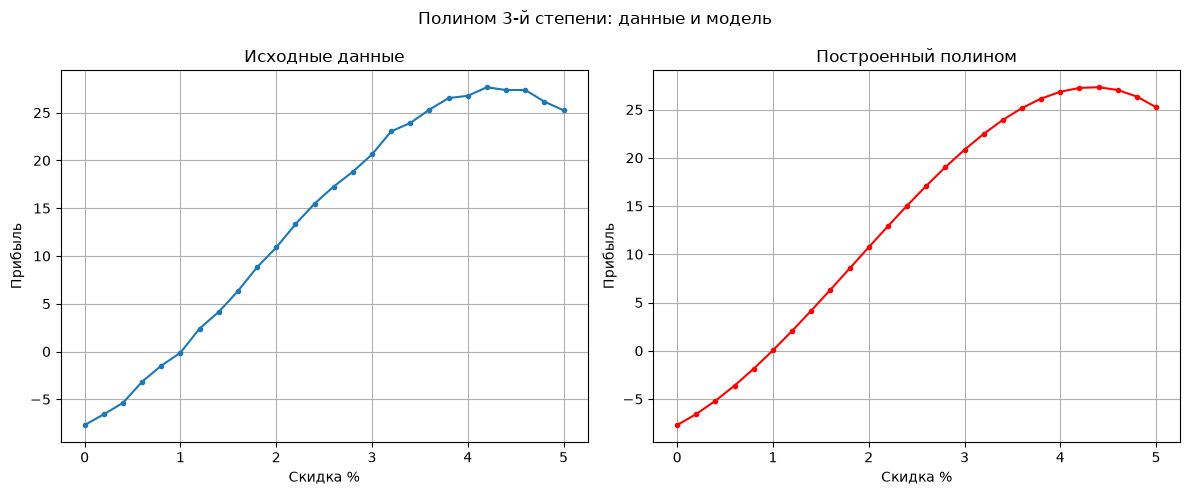

In [114]:
fig2, axs2 = plt.subplots(1, 2, figsize=(12, 5))
fig2.suptitle('Полином 3-й степени: данные и модель')
axs2[0].plot(x, y, marker='.')
axs2[0].set_title('Исходные данные')
axs2[0].set(xlabel='Скидка %', ylabel='Прибыль')
axs2[0].grid(True)
axs2[1].plot(x, y_fit3, color='red', marker='.')
axs2[1].set_title('Построенный полином')
axs2[1].set(xlabel='Скидка %', ylabel='Прибыль')
axs2[1].grid(True)
plt.tight_layout()
plt.show()

8. Выберите тот вариант, где значение отклонения (RSS) получается наименьшим. Для этого варианта посчитайте ожидаемое значение прибыли при значениях скидки в 6 и 8 процентов. 

In [115]:
best_coeffs, best_name, best_rss = (c3, 'Полином 3-й степени', rss3) if rss3 <= rss2 else (c2, 'Полином 2-й степени', rss2)
profit_6 = np.polyval(best_coeffs, 6)
profit_8 = np.polyval(best_coeffs, 8)

In [117]:
print(f'Лучшие значение RSS у модели: "{best_name}"\nЗначение RSS: {best_rss:.3f}\nПрибыль при 6%: {profit_6:.2f}\nПрибыль при 8%: {profit_8:.2f}')

Лучшие значение RSS у модели: "Полином 3-й степени"
Значение RSS: 1.954
Прибыль при 6%: 12.52
Прибыль при 8%: -60.34
